<a href="https://colab.research.google.com/github/hazalbese7/telecom-customer-churn-prediction/blob/main/02_Churn_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction — Machine Learning

**Author:** Hazal Beşe  
**Dataset:** IBM Telco Customer Churn  
**Tools:** Python, Pandas, Scikit-learn, Google Colab

## Project Objective

This notebook develops and evaluates a machine learning model to predict customer churn using a publicly available telecommunications dataset.

The workflow includes data preparation, stratified train-validation-test splitting, Logistic Regression, feature expansion, classification threshold comparison, and final model evaluation.

The main objective is to improve the detection of customers at risk of churn while examining the trade-off between precision and recall.

**Note:** This is an independent educational project using public data, not actual Vodafone customer information.

## 1. Data Loading and Inspection

The IBM Telco Customer Churn dataset is loaded using Pandas.

The dataset contains 7,043 customer records. We inspect its structure, column names, data types, and missing values before preparing the data for machine learning.

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df.info()

Dataset shape: (7043, 21)
Missing values: 0
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-

## 2. Target and Feature Selection

The target variable, `Churn`, is converted into a binary numerical variable named `Churn_Binary`, where 0 represents a customer who stayed and 1 represents a customer who churned.

We first build a baseline model using three features, then expand the feature set to investigate whether additional customer information improves predictive performance.

In [3]:
df["Churn_Binary"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

X = df[["tenure", "MonthlyCharges", "Contract"]]
y = df["Churn_Binary"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 3)
Target: (7043,)


## 3. Train / Validation / Test Split

The dataset is initially split into 80% training and 20% testing, using stratification to preserve the churn class distribution.

The initial training data is further divided into development and validation subsets.

- **Development:** Used for model training.
- **Validation:** Used for feature-set and threshold comparison.
- **Test:** Reserved for evaluating the selected approach.

A fixed random state ensures reproducible data splits.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### 3.1 Expanded Feature Set

Five additional categorical features are introduced to evaluate whether more customer information improves churn prediction.

The original training and test customer assignments are preserved using their row indices.

In [5]:
expanded_features = [
    "tenure",
    "MonthlyCharges",
    "Contract",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod",
    "PaperlessBilling"
]

X_train_expanded = df.loc[X_train.index, expanded_features]
X_test_expanded = df.loc[X_test.index, expanded_features]

### 3.2 Validation Split

The original training set is split again to create a separate validation group.

This allows model configurations and decision thresholds to be compared without using the test set during model development.

In [6]:
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train_expanded,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Development features:", X_dev.shape)
print("Validation features:", X_val.shape)
print("Development target:", y_dev.shape)
print("Validation target:", y_val.shape)
print("Final test features:", X_test_expanded.shape)

Development features: (4225, 8)
Validation features: (1409, 8)
Development target: (4225,)
Validation target: (1409,)
Final test features: (1409, 8)


## 4. Baseline Model — Three Features

A Logistic Regression baseline is trained using three features:

- tenure
- MonthlyCharges
- Contract

Numerical features are standardized, while the categorical feature is encoded using One-Hot Encoding.

A Scikit-learn Pipeline keeps preprocessing and modeling together, reducing the risk of data leakage.

In [7]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [8]:
numerical_features = ["tenure", "MonthlyCharges"]
categorical_features = ["Contract"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [9]:
X_dev_basic = X_dev[["tenure", "MonthlyCharges", "Contract"]]
X_val_basic = X_val[["tenure", "MonthlyCharges", "Contract"]]

basic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

basic_pipeline.fit(X_dev_basic, y_dev)

y_val_pred_basic = basic_pipeline.predict(X_val_basic)

In [10]:
basic_val_accuracy = accuracy_score(y_val, y_val_pred_basic)
basic_val_precision = precision_score(y_val, y_val_pred_basic)
basic_val_recall = recall_score(y_val, y_val_pred_basic)
basic_val_f1 = f1_score(y_val, y_val_pred_basic)

print("Basic Model Accuracy:", round(basic_val_accuracy, 4))
print("Basic Model Precision:", round(basic_val_precision, 4))
print("Basic Model Recall:", round(basic_val_recall, 4))
print("Basic Model F1-score:", round(basic_val_f1, 4))

Basic Model Accuracy: 0.7942
Basic Model Precision: 0.6458
Basic Model Recall: 0.4973
Basic Model F1-score: 0.5619


## 5. Expanded Model — Eight Features

The baseline feature set is expanded from three to eight variables.

Additional features include internet service, online security, technical support, payment method, and paperless billing.

Both models are trained and evaluated using the same development and validation customer groups, enabling a more consistent comparison.

In [11]:
categorical_features_expanded = [
    "Contract",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod",
    "PaperlessBilling"
]

preprocessor_expanded = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_expanded)
    ]
)

In [12]:
expanded_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_expanded),
    ("classifier", LogisticRegression(max_iter=1000))
])

expanded_pipeline.fit(X_dev, y_dev)

y_val_pred = expanded_pipeline.predict(X_val)

In [13]:
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)
val_recall = recall_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred)

print("Expanded Accuracy:", round(val_accuracy, 4))
print("Expanded Precision:", round(val_precision, 4))
print("Expanded Recall:", round(val_recall, 4))
print("Expanded F1-score:", round(val_f1, 4))

Expanded Accuracy: 0.7984
Expanded Precision: 0.6552
Expanded Recall: 0.508
Expanded F1-score: 0.5723


In [14]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Baseline (3 features)": [
        basic_val_accuracy,
        basic_val_precision,
        basic_val_recall,
        basic_val_f1
    ],
    "Expanded (8 features)": [
        val_accuracy,
        val_precision,
        val_recall,
        val_f1
    ]
})

comparison.round(4)

,Metric,Baseline (3 features),Expanded (8 features)
0,Accuracy,0.7942,0.7984
1,Precision,0.6458,0.6552
2,Recall,0.4973,0.5080
3,F1-score,0.5619,0.5723


### Feature Comparison Findings

The eight-feature model showed modest improvements over the three-feature baseline across accuracy, precision, recall, and F1-score on the same validation set.

The improvement suggests that additional customer characteristics provide some useful predictive information. However, the gain is relatively small, and generalization to other datasets is not guaranteed.

## 6. Classification Threshold Comparison

The default classification threshold of Logistic Regression is 0.50.

To investigate whether more churned customers can be identified, thresholds of 0.50 and 0.40 are compared using validation predictions.

A lower threshold can improve recall but may increase false-positive predictions.

Threshold selection is performed using validation data rather than test data.

In [15]:
val_probabilities = expanded_pipeline.predict_proba(X_val)

churn_probabilities = val_probabilities[:, 1]

y_pred_50 = (churn_probabilities >= 0.50).astype(int)
y_pred_40 = (churn_probabilities >= 0.40).astype(int)

In [16]:
threshold_results = []

for threshold, predictions in [(0.50, y_pred_50), (0.40, y_pred_40)]:
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions)
    })

threshold_comparison = pd.DataFrame(threshold_results)

threshold_comparison.round(4)

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.5,0.7984,0.6552,0.5080,0.5723
1,0.4,0.7977,0.6072,0.6738,0.6388


### Threshold Comparison Findings

Reducing the threshold from 0.50 to 0.40 increased validation recall from approximately 50.80% to 67.38%.

The F1-score increased from approximately 57.23% to 63.88%, while precision decreased from approximately 65.52% to 60.72%.

This illustrates the trade-off between identifying more churned customers and generating additional false positives.

Based on this validation comparison and the objective of detecting more at-risk customers, a threshold of 0.40 was selected for final evaluation.

## 7. Final Model Training and Evaluation

After comparing feature sets and classification thresholds on the validation data, the final approach was selected:

- Eight customer features
- Logistic Regression
- Classification threshold: 0.40

The selected pipeline is retrained on the complete original training set, containing 5,634 customers.

The reserved test set is then used for a final evaluation without changing the selected configuration based on its results.

In [17]:
final_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_expanded),
    ("classifier", LogisticRegression(max_iter=1000))
])

final_pipeline.fit(X_train_expanded, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Contract',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'TechSupport',
                                                   'PaymentMethod',
                                                   'PaperlessBilling'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [18]:
test_probabilities = final_pipeline.predict_proba(X_test_expanded)

test_churn_probabilities = test_probabilities[:, 1]

y_test_pred_final = (test_churn_probabilities >= 0.40).astype(int)

In [19]:
final_accuracy = accuracy_score(y_test, y_test_pred_final)
final_precision = precision_score(y_test, y_test_pred_final)
final_recall = recall_score(y_test, y_test_pred_final)
final_f1 = f1_score(y_test, y_test_pred_final)

print("Final Accuracy:", round(final_accuracy, 4))
print("Final Precision:", round(final_precision, 4))
print("Final Recall:", round(final_recall, 4))
print("Final F1-score:", round(final_f1, 4))

Final Accuracy: 0.7722
Final Precision: 0.5621
Final Recall: 0.6417
Final F1-score: 0.5993


In [20]:
final_cm = confusion_matrix(y_test, y_test_pred_final)

print("Final Confusion Matrix:")
print(final_cm)

Final Confusion Matrix:
[[848 187]
 [134 240]]


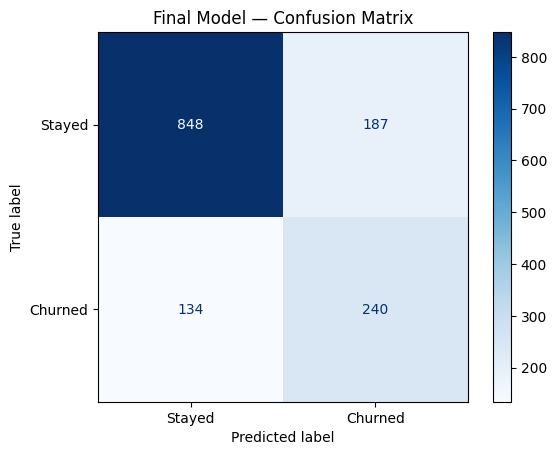

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Final Model — Confusion Matrix")
plt.show()

### Final Test Results

The final eight-feature Logistic Regression model achieved:

- Accuracy: 77.22%
- Precision: 56.21%
- Recall: 64.17%
- F1-score: 59.93%

The confusion matrix showed:

- True Negatives: 848
- False Positives: 187
- False Negatives: 134
- True Positives: 240

The model correctly identified 240 of the 374 customers who actually churned.

Compared with the initial three-feature model using the default threshold, the final model identified 57 additional churned customers, while generating 63 additional false positives.

This reflects a trade-off between improved churn detection and reduced precision.

## 8. Key Findings and Limitations

### Key Findings

1. Expanding the feature set from three to eight variables provided modest validation performance improvements.

2. Reducing the classification threshold from 0.50 to 0.40 increased recall substantially on the validation set.

3. On the final test set, the selected model achieved 64.17% recall and 59.93% F1-score.

4. The final model identified more customers who churned than the initial baseline, at the cost of additional false positives.

### Limitations

- The dataset is public and educational and may not represent current real-world telecommunications customers.
- Only Logistic Regression was evaluated; other algorithms may offer different performance.
- The classification threshold was selected using a single validation split rather than cross-validation.
- The original baseline was evaluated on the test set before the validation workflow was introduced. Although subsequent model selection used validation data, the test set cannot be considered entirely untouched throughout the project.
- Recall and precision have operational costs that would need to be evaluated before using the model for real customer retention decisions.

### Future Improvements

- Evaluate additional models such as Random Forest.
- Use cross-validation for more robust model selection.
- Examine ROC-AUC and Precision-Recall curves.
- Investigate model interpretability and feature importance.
- Consider the business costs of missed churn and unnecessary retention offers.

## Conclusion

This project demonstrates an end-to-end introductory machine learning workflow, from feature selection and preprocessing to model comparison, threshold analysis, and final evaluation.

The results show that classification thresholds can meaningfully influence customer churn detection and should be selected according to the intended business objective.